## Import dan Konfigurasi

In [1]:
import os, json, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score
)
import seaborn as sns

# ---- Hyperparameter & Path ----
SEED         = 42
BATCH_SIZE   = 32
LR_HEAD      = 0.001   # Tahap 1: hanya head
LR_FINETUNE  = 0.0001  # Tahap 2: fine-tune semua
EPOCHS_HEAD  = 5       # Tahap 1
EPOCHS_FINE  = 15      # Tahap 2
PATIENCE     = 7
NUM_CLASSES  = 4
IMG_SIZE     = 224
MODEL_NAME   = 'googlenet'

NOTEBOOK_DIR = Path(r'C:\Users\Bunga Alyssa\OneDrive\文档\DS\smt  7\deep l\uas\frontend\coin_new\notebook')
DIAGRAM_DIR  = Path(r'C:\Users\Bunga Alyssa\OneDrive\文档\DS\smt  7\deep l\uas\frontend\coin_new\diagram')
DIAGRAM_DIR.mkdir(parents=True, exist_ok=True)

# ---- Seed ----
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
print(f'PyTorch: {torch.__version__}')

Device: cpu
PyTorch: 2.12.0+cpu


## Muat Split

In [2]:
df_split = pd.read_csv(NOTEBOOK_DIR / 'split.csv')

CLASSES    = sorted(df_split['label'].unique())
CLASS2IDX  = {c: i for i, c in enumerate(CLASSES)}
IDX2CLASS  = {i: c for c, i in CLASS2IDX.items()}

df_train = df_split[df_split['subset'] == 'train'].reset_index(drop=True)
df_val   = df_split[df_split['subset'] == 'val'].reset_index(drop=True)
df_test  = df_split[df_split['subset'] == 'test'].reset_index(drop=True)

print(f'Classes : {CLASSES}')
print(f'Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}')

Classes : ['Rp100', 'Rp1000', 'Rp200', 'Rp500']
Train: 414 | Val: 89 | Test: 89


## Dataset dan DataLoader

In [3]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomRotation(360),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.5)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.2)),
])

val_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class CoinDataset(Dataset):
    def __init__(self, df, class2idx, transform=None):
        self.df = df.reset_index(drop=True)
        self.class2idx = class2idx
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row['path']).convert('RGB')
        if self.transform:
            img = self.transform(img)
        label = self.class2idx[row['label']]
        return img, label

train_ds = CoinDataset(df_train, CLASS2IDX, train_tf)
val_ds   = CoinDataset(df_val,   CLASS2IDX, val_tf)
test_ds  = CoinDataset(df_test,  CLASS2IDX, val_tf)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f'Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}')


Train batches: 13 | Val batches: 3 | Test batches: 3


## Hitung Class Weight

In [4]:
from sklearn.utils.class_weight import compute_class_weight

train_labels = [CLASS2IDX[l] for l in df_train['label']]
cw = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=train_labels)
class_weights = torch.tensor(cw, dtype=torch.float32).to(DEVICE)
print('Class weights:', {IDX2CLASS[i]: round(float(w), 4) for i, w in enumerate(class_weights)})

Class weights: {'Rp100': 1.0147, 'Rp1000': 1.0455, 'Rp200': 0.9079, 'Rp500': 1.0455}


## Definisi Model GoogLeNet

In [5]:
# Load pretrained, lalu nonaktifkan aux_logits setelah load
model = models.googlenet(weights=models.GoogLeNet_Weights.IMAGENET1K_V1)
model.aux_logits = False
model.aux1 = None
model.aux2 = None

# Ganti layer fc terakhir
in_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(in_features, NUM_CLASSES)
)

model = model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params     : {total_params:,}')
print(f'Trainable params : {trainable_params:,}')

Total params     : 5,604,004
Trainable params : 5,604,004


## Tahap 1: Latih Head (Backbone Beku)

In [6]:
# Bekukan semua kecuali fc
for name, param in model.named_parameters():
    if 'fc' not in name:
        param.requires_grad = False

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LR_HEAD)

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_loss = float('inf')
best_model_path = DIAGRAM_DIR / f'best_{MODEL_NAME}.pt'

print('=== Tahap 1: Melatih Head ===')
t_start = time.time()

for epoch in range(1, EPOCHS_HEAD + 1):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        out = model(imgs)
        loss = criterion(out, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * imgs.size(0)
        correct += (out.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    train_loss = running_loss / total
    train_acc  = correct / total

    model.eval()
    v_loss, v_correct, v_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            out = model(imgs)
            v_loss    += criterion(out, labels).item() * imgs.size(0)
            v_correct += (out.argmax(1) == labels).sum().item()
            v_total   += imgs.size(0)
    val_loss = v_loss / v_total
    val_acc  = v_correct / v_total

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), best_model_path)

    print(f'Tahap1 Epoch {epoch}/{EPOCHS_HEAD} | Train Loss:{train_loss:.4f} Acc:{train_acc:.4f} | Val Loss:{val_loss:.4f} Acc:{val_acc:.4f}')

print('Tahap 1 selesai.')

=== Tahap 1: Melatih Head ===


C:\Users\Bunga Alyssa\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Tahap1 Epoch 1/5 | Train Loss:1.3923 Acc:0.2633 | Val Loss:1.2664 Acc:0.5506


Tahap1 Epoch 2/5 | Train Loss:1.2291 Acc:0.4227 | Val Loss:1.1985 Acc:0.4607


Tahap1 Epoch 3/5 | Train Loss:1.1396 Acc:0.5121 | Val Loss:1.1357 Acc:0.5506


Tahap1 Epoch 4/5 | Train Loss:1.1027 Acc:0.5435 | Val Loss:1.0862 Acc:0.5393


Tahap1 Epoch 5/5 | Train Loss:1.0419 Acc:0.5749 | Val Loss:1.0597 Acc:0.5843
Tahap 1 selesai.


## Tahap 2: Fine-tune Semua Layer

In [7]:
# Unfreeze semua layer
for param in model.parameters():
    param.requires_grad = True

optimizer  = optim.Adam(model.parameters(), lr=LR_FINETUNE)
scheduler  = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=4)
patience_counter = 0

print('=== Tahap 2: Fine-tune Semua Layer ===')

for epoch in range(1, EPOCHS_FINE + 1):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        out = model(imgs)
        loss = criterion(out, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * imgs.size(0)
        correct += (out.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    train_loss = running_loss / total
    train_acc  = correct / total

    model.eval()
    v_loss, v_correct, v_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            out = model(imgs)
            v_loss    += criterion(out, labels).item() * imgs.size(0)
            v_correct += (out.argmax(1) == labels).sum().item()
            v_total   += imgs.size(0)
    val_loss = v_loss / v_total
    val_acc  = v_correct / v_total

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    scheduler.step(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(model.state_dict(), best_model_path)
    else:
        patience_counter += 1

    print(f'Tahap2 Epoch {epoch}/{EPOCHS_FINE} | Train Loss:{train_loss:.4f} Acc:{train_acc:.4f} | Val Loss:{val_loss:.4f} Acc:{val_acc:.4f} | Patience:{patience_counter}/{PATIENCE}')

    if patience_counter >= PATIENCE:
        print(f'Early stopping at Tahap2 epoch {epoch}')
        break

total_train_time = time.time() - t_start
print(f'\nTotal training time: {total_train_time:.1f}s ({total_train_time/60:.2f} min)')

=== Tahap 2: Fine-tune Semua Layer ===


Tahap2 Epoch 1/15 | Train Loss:0.9073 Acc:0.6570 | Val Loss:0.8868 Acc:0.6404 | Patience:0/7


Tahap2 Epoch 2/15 | Train Loss:0.6584 Acc:0.7633 | Val Loss:0.6624 Acc:0.7640 | Patience:0/7


Tahap2 Epoch 3/15 | Train Loss:0.4841 Acc:0.8647 | Val Loss:0.5660 Acc:0.7753 | Patience:0/7


Tahap2 Epoch 4/15 | Train Loss:0.3662 Acc:0.9106 | Val Loss:0.4843 Acc:0.8090 | Patience:0/7


Tahap2 Epoch 5/15 | Train Loss:0.2770 Acc:0.9324 | Val Loss:0.4301 Acc:0.8427 | Patience:0/7


... (6 outputs left out)

Tahap2 Epoch 12/15 | Train Loss:0.0936 Acc:0.9783 | Val Loss:0.2444 Acc:0.9326 | Patience:1/7


Tahap2 Epoch 13/15 | Train Loss:0.0956 Acc:0.9686 | Val Loss:0.2300 Acc:0.9326 | Patience:2/7


Tahap2 Epoch 14/15 | Train Loss:0.0896 Acc:0.9783 | Val Loss:0.2234 Acc:0.9101 | Patience:0/7


Tahap2 Epoch 15/15 | Train Loss:0.0671 Acc:0.9807 | Val Loss:0.2337 Acc:0.9213 | Patience:1/7

Total training time: 935.6s (15.59 min)


## Plot Kurva Training

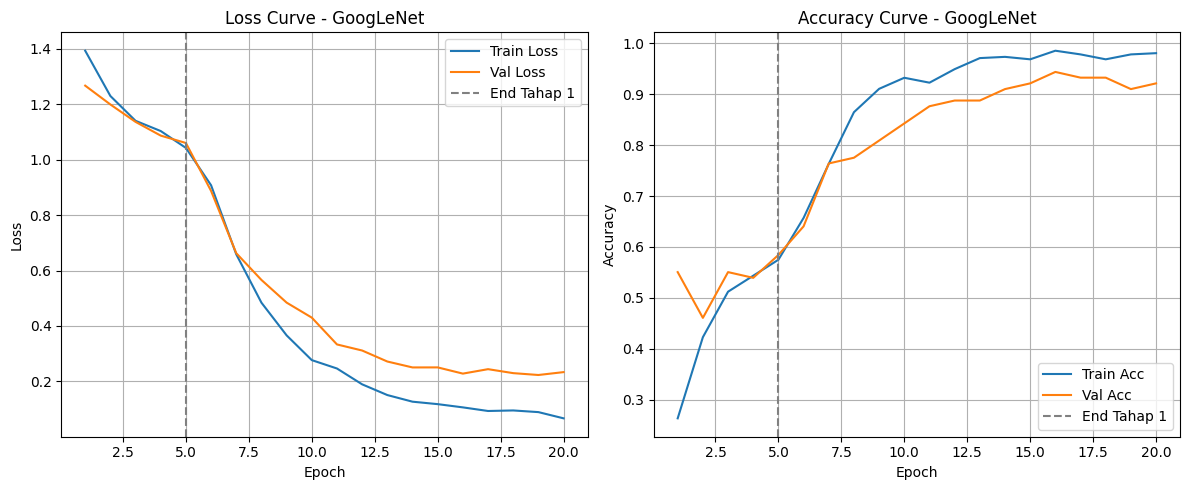

Kurva training tersimpan.


In [8]:
epochs_ran = list(range(1, len(history['train_loss']) + 1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(epochs_ran, history['train_loss'], label='Train Loss')
ax1.plot(epochs_ran, history['val_loss'],   label='Val Loss')
ax1.axvline(x=EPOCHS_HEAD, color='gray', linestyle='--', label='End Tahap 1')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax1.set_title('Loss Curve - GoogLeNet')
ax1.legend(); ax1.grid(True)

ax2.plot(epochs_ran, history['train_acc'], label='Train Acc')
ax2.plot(epochs_ran, history['val_acc'],   label='Val Acc')
ax2.axvline(x=EPOCHS_HEAD, color='gray', linestyle='--', label='End Tahap 1')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy')
ax2.set_title('Accuracy Curve - GoogLeNet')
ax2.legend(); ax2.grid(True)

plt.tight_layout()
plt.savefig(DIAGRAM_DIR / f'kurva_{MODEL_NAME}.png', dpi=150)
plt.show()
print('Kurva training tersimpan.')

## Evaluasi Test Set

In [9]:
model.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(DEVICE)
        out  = model(imgs)
        preds = out.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

acc  = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds, average='macro', zero_division=0)
rec  = recall_score(all_labels, all_preds, average='macro', zero_division=0)
f1   = f1_score(all_labels, all_preds, average='macro', zero_division=0)

print(f'Test Accuracy : {acc:.4f}')
print(f'Test Precision: {prec:.4f}')
print(f'Test Recall   : {rec:.4f}')
print(f'Test F1 (macro): {f1:.4f}')
print()
print(classification_report(all_labels, all_preds, target_names=CLASSES, zero_division=0))

Test Accuracy : 0.9438
Test Precision: 0.9495
Test Recall   : 0.9429
Test F1 (macro): 0.9450

              precision    recall  f1-score   support

       Rp100       0.88      0.95      0.91        22
      Rp1000       1.00      0.90      0.95        21
       Rp200       0.92      0.96      0.94        25
       Rp500       1.00      0.95      0.98        21

    accuracy                           0.94        89
   macro avg       0.95      0.94      0.94        89
weighted avg       0.95      0.94      0.94        89



## Confusion Matrix

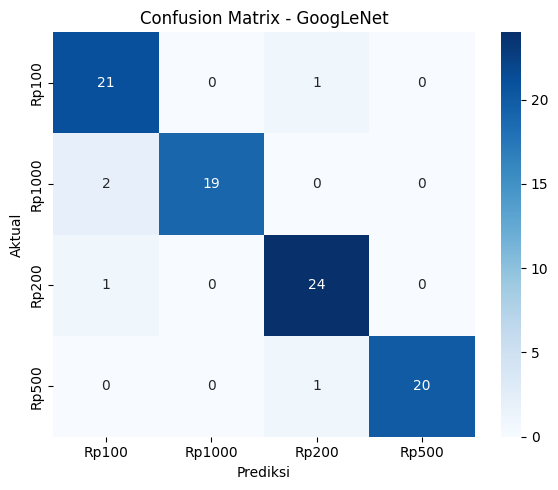

Confusion matrix tersimpan.


In [10]:
cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
ax.set_title('Confusion Matrix - GoogLeNet')
plt.tight_layout()
plt.savefig(DIAGRAM_DIR / f'cm_{MODEL_NAME}.png', dpi=150)
plt.show()
print('Confusion matrix tersimpan.')

## Inferensi dan Ukuran Model

In [11]:
model.eval()
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
for _ in range(10):
    with torch.no_grad():
        _ = model(dummy)

N_RUNS = 100
t0 = time.time()
for _ in range(N_RUNS):
    with torch.no_grad():
        _ = model(dummy)
infer_time_ms = (time.time() - t0) / N_RUNS * 1000

model_size_mb = os.path.getsize(best_model_path) / (1024 ** 2)

print(f'Inferensi rata-rata : {infer_time_ms:.3f} ms/gambar')
print(f'Total parameter     : {total_params:,}')
print(f'Ukuran model (.pt)  : {model_size_mb:.2f} MB')

Inferensi rata-rata : 48.315 ms/gambar
Total parameter     : 5,604,004
Ukuran model (.pt)  : 21.54 MB


## Contoh Gambar Salah Prediksi

Jumlah salah prediksi: 5


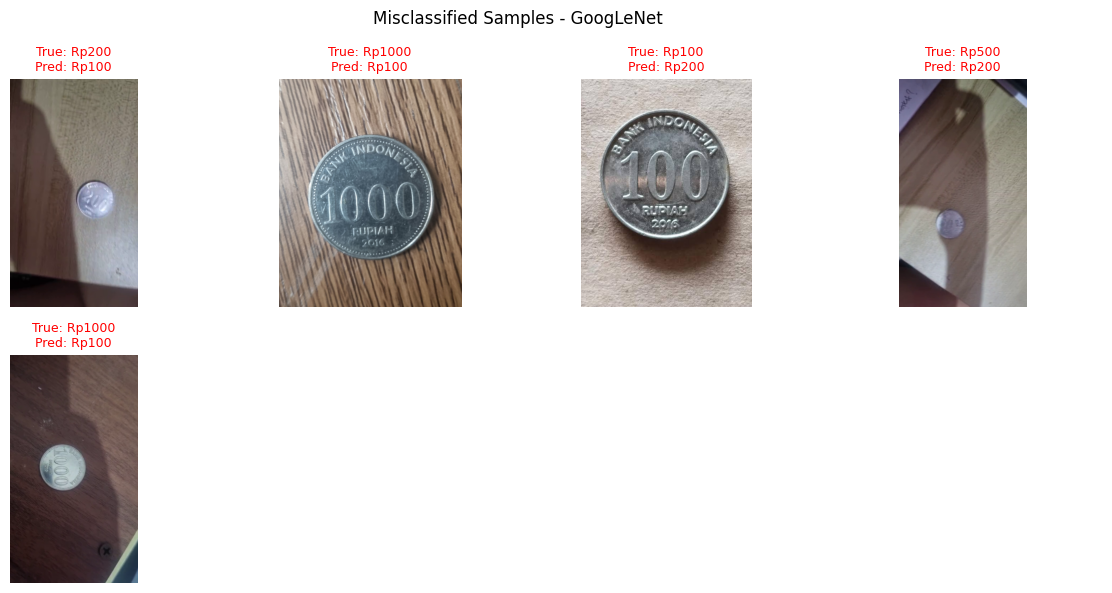

In [12]:
wrong_idxs = np.where(all_preds != all_labels)[0]
print(f'Jumlah salah prediksi: {len(wrong_idxs)}')

show_idxs = wrong_idxs[:12]
if len(show_idxs) > 0:
    ncols = min(4, len(show_idxs))
    nrows = (len(show_idxs) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3, nrows * 3))
    axes = np.array(axes).flatten()

    for i, idx in enumerate(show_idxs):
        img_path = df_test.iloc[idx]['path']
        img = Image.open(img_path).convert('RGB')
        axes[i].imshow(img)
        axes[i].set_title(
            f'True: {IDX2CLASS[all_labels[idx]]}\nPred: {IDX2CLASS[all_preds[idx]]}',
            fontsize=9, color='red'
        )
        axes[i].axis('off')

    for j in range(len(show_idxs), len(axes)):
        axes[j].axis('off')

    plt.suptitle('Misclassified Samples - GoogLeNet', fontsize=12)
    plt.tight_layout()
    plt.savefig(DIAGRAM_DIR / f'misclassified_{MODEL_NAME}.png', dpi=150)
    plt.show()
else:
    print('Tidak ada gambar salah prediksi!')

## Simpan Metrik JSON

In [13]:
f1_per_class   = f1_score(all_labels, all_preds, average=None, zero_division=0).tolist()
prec_per_class = precision_score(all_labels, all_preds, average=None, zero_division=0).tolist()
rec_per_class  = recall_score(all_labels, all_preds, average=None, zero_division=0).tolist()

metrics = {
    'model': MODEL_NAME,
    'accuracy': float(acc),
    'precision_macro': float(prec),
    'recall_macro': float(rec),
    'f1_macro': float(f1),
    'per_class': {
        cls: {
            'precision': round(prec_per_class[i], 4),
            'recall': round(rec_per_class[i], 4),
            'f1': round(f1_per_class[i], 4),
        }
        for i, cls in enumerate(CLASSES)
    },
    'confusion_matrix': cm.tolist(),
    'total_params': total_params,
    'model_size_mb': round(model_size_mb, 4),
    'infer_time_ms': round(infer_time_ms, 4),
    'training_time_s': round(total_train_time, 2),
    'best_epoch': len(history['train_loss']),
    'history': history,
    'classes': CLASSES,
    'hyperparams': {
        'batch_size': BATCH_SIZE,
        'lr_head': LR_HEAD,
        'lr_finetune': LR_FINETUNE,
        'epochs_head': EPOCHS_HEAD,
        'epochs_finetune': EPOCHS_FINE,
        'patience': PATIENCE,
        'optimizer': 'Adam',
    }
}

metrics_path = DIAGRAM_DIR / f'metrics_{MODEL_NAME}.json'
with open(metrics_path, 'w') as f:
    json.dump(metrics, f, indent=2)

print(f'Metrik disimpan ke: {metrics_path}')
print(f'Accuracy : {acc:.4f}')
print(f'F1 Macro : {f1:.4f}')

Metrik disimpan ke: C:\Users\Bunga Alyssa\OneDrive\文档\DS\smt  7\deep l\uas\frontend\coin_new\diagram\metrics_googlenet.json
Accuracy : 0.9438
F1 Macro : 0.9450
